# 02 · Pre-Processing & Augmentation Pipeline
**Intel Scene Classification with a CNN Trained From Scratch (TensorFlow / Keras)**  
*Section 2* · MSc Data Science project · Dr. Spoorthi H S

**In this notebook**
- Stratified train/validation split (11,928 / 2,106)
- tf.data pipeline: decode, resize, flips, zoom, colour jitter, random erasing, prefetch
- Batch-level MixUp and CutMix with soft labels
- Raw vs augmented comparisons and augmentation-diversity grid

> **How to use these notebooks.** The outputs below come from one complete training run on a Kaggle Tesla T4 GPU. Each part builds on objects created earlier (configuration, data pipelines, the trained model), so the part notebooks are for reading and review. To reproduce the results, run [`00_full_pipeline_run_all.ipynb`](00_full_pipeline_run_all.ipynb) top to bottom.

[← Problem Definition & Exploratory Data Analysis](01_problem_definition_and_eda.ipynb) · [Model Design: DeepSceneNet →](03_model_architecture.ipynb)

---

---
## 2️⃣ Data Pre-Processing & Input Pipeline

### 2.1 Stratified Train / Val Split
We use `StratifiedShuffleSplit` to preserve class balance in both subsets.


In [ ]:
def gather(root):
    paths, labels = [], []
    for cls in CFG["CLASSES"]:
        for p in sorted((root/cls).glob("*.jpg")):
            paths.append(str(p)); labels.append(CLASS_TO_IDX[cls])
    return np.array(paths), np.array(labels)

all_tr_p, all_tr_l = gather(CFG["TRAIN_DIR"])
test_p,   test_l   = gather(CFG["TEST_DIR"])

sss = StratifiedShuffleSplit(n_splits=1,
                              test_size=CFG["VAL_SPLIT"],
                              random_state=SEED)
tr_idx, val_idx  = next(sss.split(all_tr_p, all_tr_l))
tr_p,  tr_l      = all_tr_p[tr_idx],  all_tr_l[tr_idx]
val_p, val_l     = all_tr_p[val_idx], all_tr_l[val_idx]

print(f"Train : {len(tr_p):,}")
print(f"Val   : {len(val_p):,}")
print(f"Test  : {len(test_p):,}")
print(f"Train label distribution: {dict(sorted(Counter(tr_l).items()))}")


Train : 11,928
Val   : 2,106
Test  : 3,000
Train label distribution: {np.int64(0): 1862, np.int64(1): 1930, np.int64(2): 2043, np.int64(3): 2135, np.int64(4): 1933, np.int64(5): 2025}


### 2.2 Preprocessing & Augmentation Functions

**Training pipeline:**
```
Decode JPEG ➜ Resize 150×150 ➜ RandomFlip H/V ➜ Random Zoom (80–100%)
➜ Colour Jitter (brightness/contrast/saturation/hue) ➜ Random Erasing (Cutout)
➜ Pixel normalise [0,255] → [0,1]   ← pure normalisation, no pretrained mean/std
```
**Val / Test pipeline:**
```
Decode JPEG ➜ Resize 150×150 ➜ Pixel normalise [0,255] → [0,1]
```
> ℹ️ We normalise to [0,1] (not ImageNet mean/std) because the CNN is trained from scratch.


In [ ]:
IMG_SIZE   = CFG["IMG_SIZE"]
AUTOTUNE   = CFG["AUTOTUNE"]
BATCH_SIZE = CFG["BATCH_SIZE"]

# ─── Decode + resize ──────────────────────────────────────────────────────────
@tf.function
def decode_resize(path, label):
    raw   = tf.io.read_file(path)
    img   = tf.image.decode_jpeg(raw, channels=3)
    img   = tf.image.resize(img, [IMG_SIZE, IMG_SIZE])
    img   = tf.cast(img, tf.float32)
    return img, label

# ─── Pixel normalise [0,255] → [0,1] ─────────────────────────────────────────
@tf.function
def normalise(img, label):
    img = img / 255.0
    return img, label

# ─── One-hot encode labels ───────────────────────────────────────────────────
@tf.function
def one_hot_encode(img, label):
    return img, tf.one_hot(label, CFG["NUM_CLASSES"])

# ─── Training augmentation ────────────────────────────────────────────────────
@tf.function
def augment_train(img, label):
    # Flips
    img = tf.image.random_flip_left_right(img, seed=SEED)
    img = tf.image.random_flip_up_down(img, seed=SEED)

    # Random crop → resize  (zoom-in, 80–100 %)
    scale  = tf.random.uniform([], 0.80, 1.00, seed=SEED)
    crop_s = tf.cast(tf.cast(IMG_SIZE, tf.float32) * scale, tf.int32)
    img    = tf.image.random_crop(img, [crop_s, crop_s, 3], seed=SEED)
    img    = tf.image.resize(img, [IMG_SIZE, IMG_SIZE])

    # Colour jitter
    img = tf.image.random_brightness(img, 0.25, seed=SEED)
    img = tf.image.random_contrast(img, 0.75, 1.30, seed=SEED)
    img = tf.image.random_saturation(img, 0.70, 1.30, seed=SEED)
    img = tf.image.random_hue(img, 0.08, seed=SEED)
    img = tf.clip_by_value(img, 0.0, 255.0)

    # Random Erasing — erase one 25×25 patch
    ey   = tf.random.uniform([], 15, IMG_SIZE-25, dtype=tf.int32, seed=SEED)
    ex   = tf.random.uniform([], 15, IMG_SIZE-25, dtype=tf.int32, seed=SEED)
    ph   = pw = 25
    y2   = tf.minimum(ey + ph, IMG_SIZE)
    x2   = tf.minimum(ex + pw, IMG_SIZE)
    hole = tf.ones([y2-ey, x2-ex, 3]) * 128.0  # fill with mid-grey
    hole = tf.pad(hole,
                  [[ey, IMG_SIZE-y2],[ex, IMG_SIZE-x2],[0,0]],
                  constant_values=0.0)
    keep_mask = tf.cast(tf.equal(hole, 0.0), tf.float32)
    img  = img * keep_mask + hole * (1.0 - keep_mask)
    return img, label

### 2.3 MixUp & CutMix Augmentations

In [ ]:
# ─── MixUp ────────────────────────────────────────────────────────────────────
def mixup_batch(images, labels, alpha=CFG["MIXUP_ALPHA"]):
    """Blend two samples: x̃ = λx_i + (1-λ)x_j  (applied on normalised images)"""
    batch_size = tf.shape(images)[0]
    # Ensure lam is a Tensor and not a Generator object
    lam = tf.random.uniform(shape=[batch_size], minval=0, maxval=1, dtype=tf.float32, seed=SEED)
    lam = tf.maximum(lam, 1.0 - lam)           # keep λ > 0.5
    lam = lam[:, tf.newaxis, tf.newaxis, tf.newaxis]
    idx = tf.random.shuffle(tf.range(batch_size), seed=SEED)
    mixed_images = lam * images + (1.0-lam) * tf.gather(images, idx)
    lam_1d       = tf.squeeze(lam, [1,2,3])
    # soft labels
    one_hot      = tf.one_hot(labels, CFG["NUM_CLASSES"])
    mixed_labels = (lam_1d[:,tf.newaxis] * one_hot
                    + (1.0-lam_1d)[:,tf.newaxis] * tf.gather(one_hot,idx))
    return mixed_images, mixed_labels

# ─── CutMix ───────────────────────────────────────────────────────────────────
def cutmix_batch(images, labels, alpha=CFG["CUTMIX_ALPHA"]):
    """Paste a rectangular region from one image into another."""
    batch_size = tf.shape(images)[0]
    lam = tf.random.uniform([], 0.0, 1.0, seed=SEED)
    cut_rat  = tf.sqrt(1.0 - lam)
    cut_w    = tf.cast(IMG_SIZE * cut_rat, tf.int32)
    cut_h    = tf.cast(IMG_SIZE * cut_rat, tf.int32)
    cx = tf.random.uniform([], 0, IMG_SIZE, dtype=tf.int32, seed=SEED)
    cy = tf.random.uniform([], 0, IMG_SIZE, dtype=tf.int32, seed=SEED)
    x1 = tf.clip_by_value(cx - cut_w//2, 0, IMG_SIZE)
    y1 = tf.clip_by_value(cy - cut_h//2, 0, IMG_SIZE)
    x2 = tf.clip_by_value(cx + cut_w//2, 0, IMG_SIZE)
    y2 = tf.clip_by_value(cy + cut_h//2, 0, IMG_SIZE)
    # actual lambda after clipping
    lam_adj = 1.0 - tf.cast((x2-x1)*(y2-y1), tf.float32)/float(IMG_SIZE**2)
    idx      = tf.random.shuffle(tf.range(batch_size), seed=SEED)
    imgs_b   = tf.gather(images, idx)
    # build mask
    mask = tf.pad(tf.ones([y2-y1, x2-x1, 3]),
                  [[y1, IMG_SIZE-y2],[x1, IMG_SIZE-x2],[0,0]])
    mixed    = images*(1.0-mask) + imgs_b*mask
    one_hot  = tf.one_hot(labels, CFG["NUM_CLASSES"])
    mixed_lbl= lam_adj*one_hot + (1.0-lam_adj)*tf.gather(one_hot, idx)
    return mixed, mixed_lbl

# ─── Apply MixUp or CutMix randomly at batch level ────────────────────────────
@tf.function
def apply_mixup_cutmix(images, labels):
    choice = tf.random.uniform([], seed=SEED)
    images_norm = images / 255.0   # normalise before mixing
    mixed_img, mixed_lbl = tf.cond(
        choice < 0.5,
        lambda: mixup_batch(images_norm, labels),
        lambda: cutmix_batch(images_norm, labels)
    )
    return mixed_img, mixed_lbl


### 2.4 Build tf.data Pipelines

In [ ]:
# ─── Training dataset ─────────────────────────────────────────────────────────
def make_train_dataset(paths, labels):
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    ds = ds.shuffle(len(paths), seed=SEED, reshuffle_each_iteration=True)
    ds = ds.map(decode_resize,   num_parallel_calls=AUTOTUNE)
    ds = ds.map(augment_train,   num_parallel_calls=AUTOTUNE)
    ds = ds.batch(BATCH_SIZE, drop_remainder=True)
    ds = ds.map(apply_mixup_cutmix, num_parallel_calls=AUTOTUNE)   # MixUp/CutMix
    ds = ds.prefetch(AUTOTUNE)
    return ds

# ─── Val / Test dataset (no augmentation) ────────────────────────────────────
def make_eval_dataset(paths, labels):
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    ds = ds.map(decode_resize, num_parallel_calls=AUTOTUNE)
    ds = ds.map(normalise,     num_parallel_calls=AUTOTUNE)
    ds = ds.map(one_hot_encode, num_parallel_calls=AUTOTUNE) # Added one-hot encoding here
    ds = ds.batch(BATCH_SIZE)
    ds = ds.prefetch(AUTOTUNE)
    return ds

train_ds = make_train_dataset(tr_p, tr_l)
val_ds   = make_eval_dataset(val_p, val_l)
test_ds  = make_eval_dataset(test_p, test_l)

STEPS_PER_EPOCH = len(tr_p) // BATCH_SIZE
print(f"Steps/epoch : {STEPS_PER_EPOCH}")
print(f"Train batches: {len(train_ds)}")
print(f"Val   batches: {len(val_ds)}")
print(f"Test  batches: {len(test_ds)}")

I0000 00:00:1773799581.139354      55 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13757 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1773799581.142408      55 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13757 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Steps/epoch : 93
Train batches: 93
Val   batches: 17
Test  batches: 24


### 2.5 Visualise Preprocessed & Augmented Samples

In [ ]:
# ─── Pull one batch from training pipeline ────────────────────────────────────
sample_images, sample_labels = next(iter(train_ds))
sample_images_np = sample_images.numpy()
sample_labels_np = sample_labels.numpy()

print(f"Batch image shape : {sample_images_np.shape}")
print(f"Batch label shape : {sample_labels_np.shape}  (soft labels from MixUp/CutMix)")
print(f"Pixel range       : [{sample_images_np.min():.3f}, {sample_images_np.max():.3f}]")
print(f"Pixel mean        : {sample_images_np.mean():.4f}")
print(f"Pixel std         : {sample_images_np.std():.4f}")


2026-03-18 02:06:24.571678: E tensorflow/core/framework/node_def_util.cc:680] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_16}}


Batch image shape : (128, 150, 150, 3)
Batch label shape : (128, 6)  (soft labels from MixUp/CutMix)
Pixel range       : [0.000, 1.000]
Pixel mean        : 0.4291
Pixel std         : 0.2258


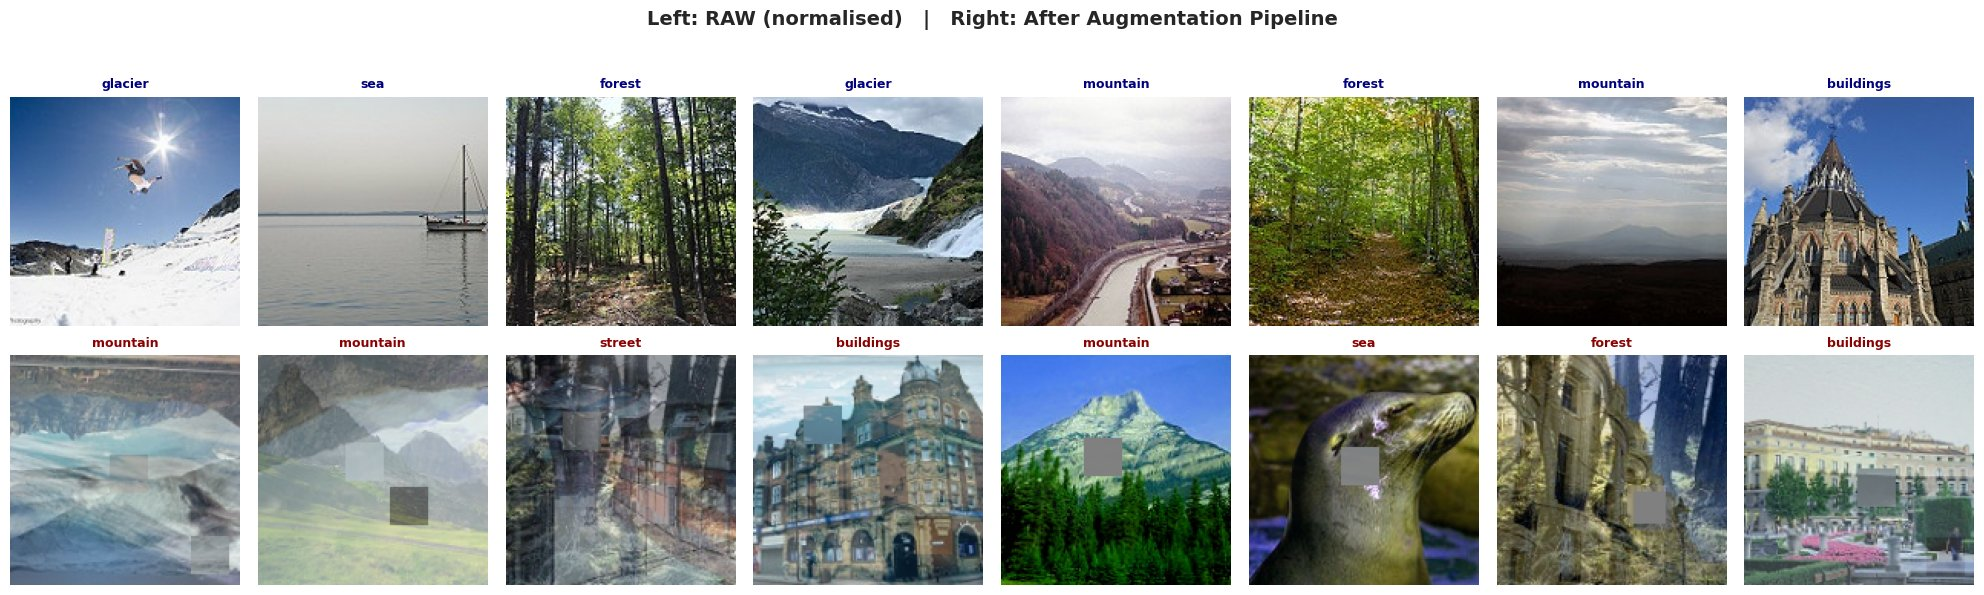

  Saved → raw_vs_augmented.png


In [ ]:
# ─── Side-by-side: RAW vs PREPROCESSED (augmented) for 8 samples ─────────────
n_show   = 8
raw_imgs = []   # load the same images without augmentation for comparison
raw_lbls = []

for i in range(n_show):
    p = tr_p[i]
    img_raw = np.array(Image.open(p).convert("RGB").resize((IMG_SIZE,IMG_SIZE)),
                       dtype=np.float32)
    raw_imgs.append(img_raw / 255.0)
    raw_lbls.append(tr_l[i])

fig, axes = plt.subplots(2, n_show, figsize=(20, 6))
fig.suptitle("Left: RAW (normalised)   |   Right: After Augmentation Pipeline",
             fontsize=14, fontweight="bold", y=1.02)

for col in range(n_show):
    # Row 0 — raw
    ax = axes[0, col]
    ax.imshow(np.clip(raw_imgs[col], 0, 1))
    ax.set_title(IDX_TO_CLASS[raw_lbls[col]], fontsize=9, fontweight="bold", color="navy")
    ax.axis("off")
    ax.set_xlabel("RAW", fontsize=8)

    # Row 1 — augmented (from batch)
    ax2 = axes[1, col]
    aug_img = np.clip(sample_images_np[col], 0, 1)
    # argmax of soft label
    aug_cls = CFG["CLASSES"][np.argmax(sample_labels_np[col])]
    ax2.imshow(aug_img)
    ax2.set_title(f"{aug_cls}", fontsize=9, fontweight="bold", color="darkred")
    ax2.axis("off")
    ax2.set_xlabel("AUGMENTED", fontsize=8)

    # Draw connecting arrow
    for axx in [ax, ax2]:
        for spine in axx.spines.values():
            spine.set_visible(True); spine.set_linewidth(1.5)
            spine.set_edgecolor("#95a5a6")

plt.tight_layout()
plt.savefig("raw_vs_augmented.png", dpi=130, bbox_inches="tight")
plt.show()
print("  Saved → raw_vs_augmented.png")


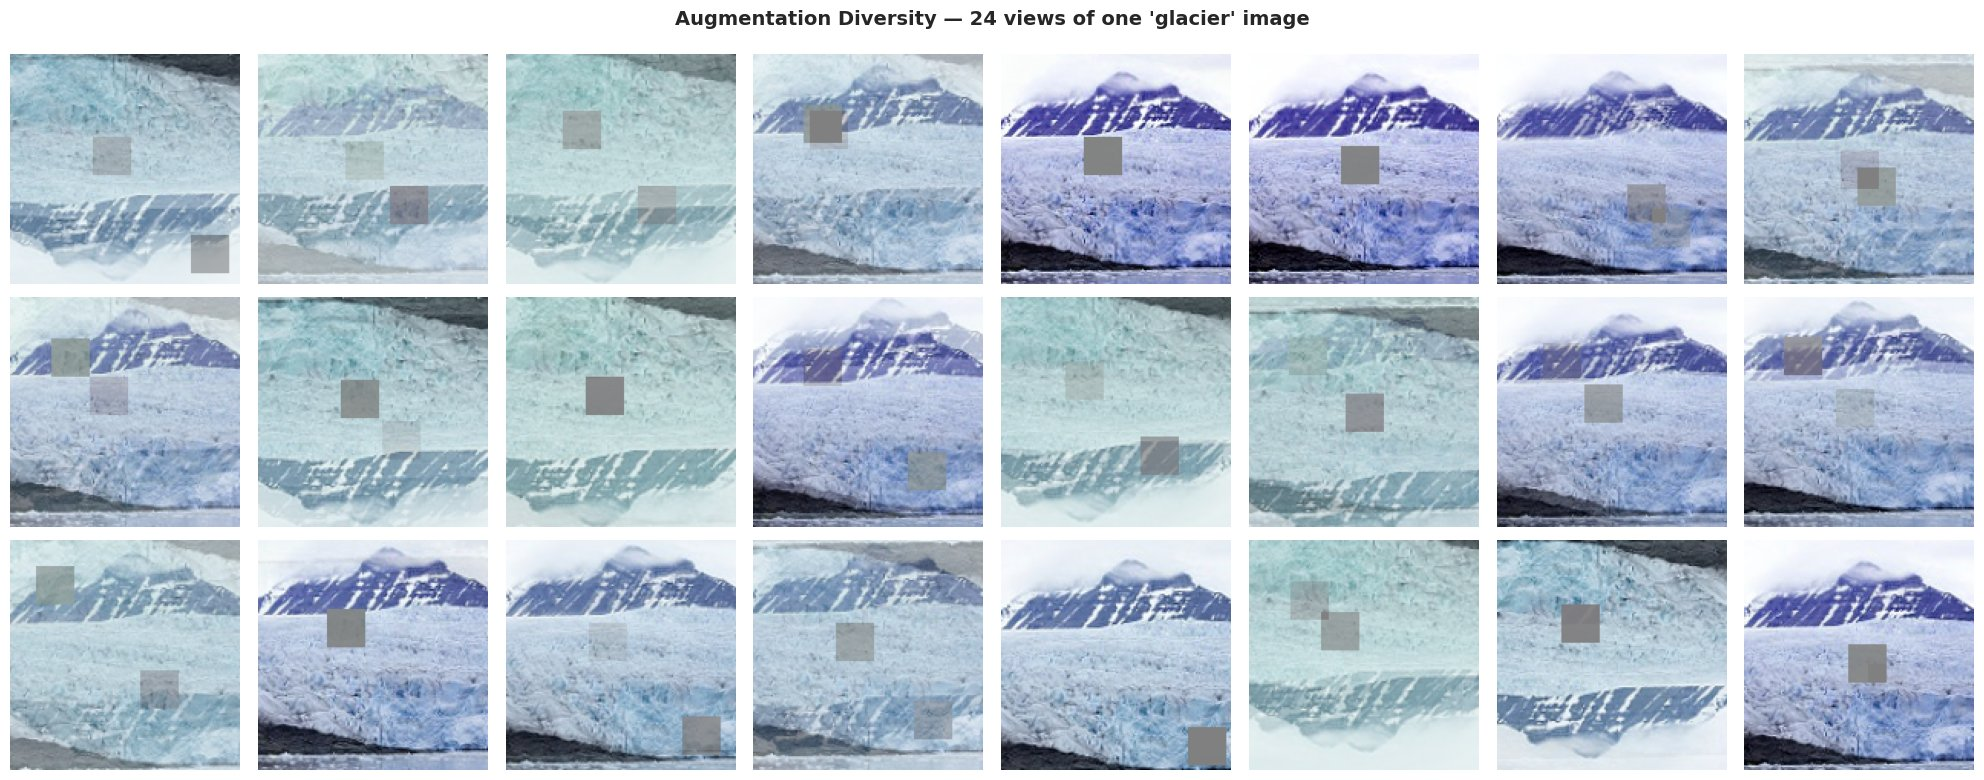

  Saved → augmentation_diversity.png


In [ ]:
# ─── Augmentation variety grid — same image, 12 different augmentations ────────
one_path  = tr_p[42]
one_label = tr_l[42]

one_ds = (tf.data.Dataset
          .from_tensor_slices(([one_path]*48, [one_label]*48))
          .map(decode_resize, num_parallel_calls=AUTOTUNE)
          .map(augment_train, num_parallel_calls=AUTOTUNE)
          .batch(48)
          .map(apply_mixup_cutmix))
aug_batch, _ = next(iter(one_ds))
aug_batch_np = aug_batch.numpy()

fig, axes = plt.subplots(3, 8, figsize=(20, 8))
fig.suptitle(f"Augmentation Diversity — 24 views of one '{IDX_TO_CLASS[one_label]}' image",
             fontsize=14, fontweight="bold")
for i, ax in enumerate(axes.flatten()):
    ax.imshow(np.clip(aug_batch_np[i], 0, 1))
    ax.axis("off")
plt.tight_layout()
plt.savefig("augmentation_diversity.png", dpi=120, bbox_inches="tight")
plt.show()
print("  Saved → augmentation_diversity.png")


---

[← Problem Definition & Exploratory Data Analysis](01_problem_definition_and_eda.ipynb) · [Next: Model Design: DeepSceneNet →](03_model_architecture.ipynb)